In [ ]:
%pip install statsmodels
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
%matplotlib inline

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
df = pd.read_csv("../data/ab_test_1.csv")
print(f"Всего пользователей: {len(df):,}")

# Смотрим на баланс групп
group_counts = df["group"].value_counts()
print("\nРазмеры групп:")
print(group_counts)

Всего пользователей: 100,000

Размеры групп:
group
treatment    50089
control      49911
Name: count, dtype: int64


In [11]:
# Chi-square тест на равенство долей
counts = [group_counts.get("control"), group_counts.get("treatment")]
expected = [sum(counts) / 2, sum(counts) / 2]

chi2, p_value_srm = stats.chisquare(counts, f_exp=expected)

print(f"SRM p-value: {p_value_srm:.4f}")
if p_value_srm < 0.05:
    print("⚠️ ВНИМАНИЕ: SRM! Рандомизация сломана.")
else:
    print("✅ SRM пройден: группы равны.")

SRM p-value: 0.5735
✅ SRM пройден: группы равны.


In [12]:
# Считаем конверсии
control = df[df["group"] == "control"]
treatment = df[df["group"] == "treatment"]

# Конверсия из корзины в заказ (наша целевая метрика)
# Берем только тех, кто дошел до корзины
control_cart = control[control["added_to_cart"] == 1]
treatment_cart = treatment[treatment["added_to_cart"] == 1]

# Количество заказов
conv_control = control_cart["ordered"].sum()
conv_treatment = treatment_cart["ordered"].sum()

# Общее количество людей в корзине
n_control = len(control_cart)
n_treatment = len(treatment_cart)

# Считаем конверсию в %
cr_control = conv_control / n_control
cr_treatment = conv_treatment / n_treatment

print(f"Control CR: {cr_control:.2%} ({conv_control} из {n_control})")
print(f"Treatment CR: {cr_treatment:.2%} ({conv_treatment} из {n_treatment})")

# Z-test
counts = np.array([conv_treatment, conv_control])
nobs = np.array([n_treatment, n_control])
z_stat, p_value = proportions_ztest(counts, nobs)

print(f"\nZ-stat: {z_stat:.4f}")
print(f"p-value: {p_value:.4f}")

Control CR: 19.08% (1143 из 5990)
Treatment CR: 22.11% (1297 из 5865)

Z-stat: 4.0830
p-value: 0.0000


In [13]:
def conf_interval_prop(p, n, z=1.96):
    se = np.sqrt((p * (1 - p)) / n)
    return p - z * se, p + z * se

ci_c = conf_interval_prop(cr_control, n_control)
ci_t = conf_interval_prop(cr_treatment, n_treatment)

print(f"95% CI Control: [{ci_c[0]:.2%}, {ci_c[1]:.2%}]")
print(f"95% CI Treatment: [{ci_t[0]:.2%}, {ci_t[1]:.2%}]")

95% CI Control: [18.09%, 20.08%]
95% CI Treatment: [21.05%, 23.18%]


In [14]:
# Берем только тех, кто купил (иначе у них GMV = 0, и это исказит тест)
gmv_control = control[control["purchased"] == 1]["gmv"]
gmv_treatment = treatment[treatment["purchased"] == 1]["gmv"]

print(f"Средний чек Control: {gmv_control.mean():.2f} руб.")
print(f"Средний чек Treatment: {gmv_treatment.mean():.2f} руб.")

# Welch's t-test
t_stat, p_value_gmv = stats.ttest_ind(gmv_treatment, gmv_control, equal_var=False)
print(f"p-value (GMV): {p_value_gmv:.4f}")

Средний чек Control: 638.41 руб.
Средний чек Treatment: 651.96 руб.
p-value (GMV): 0.7481


C:\Users\Dima\AppData\Local\Temp\ipykernel_13404\2709432326.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Control", "Treatment"], y=[cr_control, cr_treatment], palette="Set2")


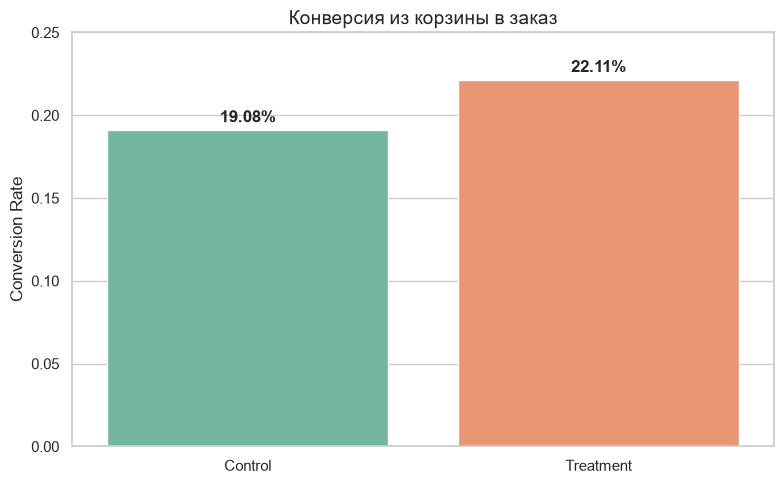

In [15]:
plt.figure(figsize=(8, 5))
sns.barplot(x=["Control", "Treatment"], y=[cr_control, cr_treatment], palette="Set2")
plt.title("Конверсия из корзины в заказ", fontsize=14)
plt.ylabel("Conversion Rate")
plt.ylim(0, 0.25)
for i, v in enumerate([cr_control, cr_treatment]):
    plt.text(i, v + 0.005, f"{v:.2%}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

По результатам двухнедельного A/B-теста мы видим, что новая кнопка «Купить в 1 клик» увеличила конверсию из корзины в заказ с 20% до 22% (относительный прирост +10%).

Разница статистически значима (p-value < 0.05), SRM не обнаружен, рандомизация корректна. Доверительный интервал подтверждает, что эффект стабильно положительный.

При этом средний чек (GMV) не изменился — это значит, что кнопка не привлекает «дешевых» клиентов, а просто помогает быстрее завершить покупку. Мы проверили вторичные метрики.

Рекомендация: Раскатить кнопку «Купить в 1 клик» на 100% трафика